## Notebook 06 — Embedding Comparison Study
**Protocol:** HANDOFF.md Section 16  
**Three embedders:** TF-IDF (sparse baseline) · all-MiniLM-L6-v2 (384-d) · all-mpnet-base-v2 (768-d)  
**Fairness controls:** identical window tokenization, same 1D-CNN head, same train/test splits, same seeds.  
**Decision metrics (priority order):**
1. Legit-encryption recall / 3-way macro-F1
2. Zero-day variant recall (all 7 Conti variants, incl. Conti_06)
3. Time-to-detection (seconds of evidence before confidence > 0.5)
4. Inference latency — **hard gate**: must sustain 10 windows/s (< 100 ms/window)
5. Embedding dimensionality / model size  

Run locally on the 6 GB GPU while waiting for Canada Alliance access (~1 week).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, pickle, json as _json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import LabelEncoder, Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, recall_score, accuracy_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sentence_transformers import SentenceTransformer
import gensim.downloader as gensim_api
import umap

PROJECT_ROOT = Path.home() / "Claude" / "Projects" / "Directed Study" / "Ransomware"
if not (PROJECT_ROOT / "features").exists():
    PROJECT_ROOT = Path.cwd()
DATA_ROOT    = PROJECT_ROOT / "dataset"
FEATURES_DIR = PROJECT_ROOT / "features"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

RANSOMWARE_CLASSES   = ["WannaCry","Ryuk","REvil","LockBit","Darkside","Conti"]
LEGIT_ENC_CLASSES    = ["AESCrypt","SDelete","Zip"]
BENIGN_CLASSES       = ["Firefox","Office","Idle"]
ALL_ORIGINAL_CLASSES = RANSOMWARE_CLASSES + LEGIT_ENC_CLASSES + BENIGN_CLASSES
VARIANT_CLASSES      = [f"Conti_{i:02d}" for i in range(1, 8)]

T_WINDOW_NS  = 100_000_000
N_WINDOWS    = 300
SEED         = 42
K_FOLDS      = 5
SEEDS        = [42, 123, 7]
EPOCHS       = 80
LR           = 1e-3
BATCH_SIZE   = 16
STATIC_DIM   = 300     # fastText pretrained vector dimension
THRESHOLD_MS = 100.0   # latency hard gate (one 0.1 s window)

def get_3way_label(cls):
    if cls in RANSOMWARE_CLASSES: return "ransomware"
    if cls in LEGIT_ENC_CLASSES:  return "legit_encryption"
    if cls in BENIGN_CLASSES:     return "benign"
    return "variant"

print("Imports loaded.")


Device: cpu
Imports loaded.


### 1. Tokenisation (identical to NB04 — fairness control)

In [3]:
def log_lines_to_text(ata_write_lines, mem_write_lines):
    tokens = []
    if ata_write_lines.empty:
        tokens.append("no storage write activity")
    else:
        for _, row in ata_write_lines.iterrows():
            size    = int(row.iloc[3]) if not pd.isna(row.iloc[3]) else 0
            entropy = float(row.iloc[4]) if not pd.isna(row.iloc[4]) else -1.0
            if entropy < 0:           ent = "unknown"
            elif entropy > 0.9:       ent = "very-high-entropy"
            elif entropy > 0.7:       ent = "high-entropy"
            elif entropy > 0.4:       ent = "moderate-entropy"
            elif entropy > 0.1:       ent = "low-entropy"
            else:                     ent = "near-zero-entropy"
            sz = "large-write" if size > 65536 else "medium-write" if size > 4096 else "small-write"
            tokens.append(f"storage-write {sz} {ent}")
    if mem_write_lines.empty:
        tokens.append("no memory write activity")
    else:
        for _, row in mem_write_lines.iterrows():
            entropy  = float(row.iloc[4]) if not pd.isna(row.iloc[4]) else 0.0
            mem_type = int(row.iloc[5])   if not pd.isna(row.iloc[5]) else 1
            tp = {1:"4kb-page", 2:"2mb-page", 4:"mmio"}.get(mem_type,"unknown-page")
            if entropy > 0.9:   ent = "very-high-entropy"
            elif entropy > 0.7: ent = "high-entropy"
            elif entropy > 0.4: ent = "moderate-entropy"
            elif entropy > 0.1: ent = "low-entropy"
            else:               ent = "near-zero-entropy"
            tokens.append(f"memory-write {tp} {ent}")
    return " . ".join(tokens[:73])   # 512-token budget cap


def extract_text_windows(exec_dir):
    ata_w, mem_w = pd.DataFrame(), pd.DataFrame()
    p = exec_dir / "ata_write.csv"
    if p.exists() and p.stat().st_size > 0:
        try: ata_w = pd.read_csv(p, header=None)
        except: pass
    p = exec_dir / "mem_write.csv"
    if p.exists() and p.stat().st_size > 0:
        try: mem_w = pd.read_csv(p, header=None)
        except: pass

    ref_ns = None
    if not ata_w.empty:
        ref_ns = int(ata_w.iloc[0,0])*1_000_000_000 + int(ata_w.iloc[0,1])
    if not mem_w.empty:
        t = int(mem_w.iloc[0,0])*1_000_000_000 + int(mem_w.iloc[0,1])
        ref_ns = t if ref_ns is None else min(ref_ns, t)
    if ref_ns is None:
        return ["no activity"] * N_WINDOWS

    if not ata_w.empty:
        ata_w = ata_w.copy()
        ata_w["rel_ns"] = (ata_w.iloc[:,0].astype(np.int64)*1_000_000_000 +
                           ata_w.iloc[:,1].astype(np.int64)) - ref_ns
    if not mem_w.empty:
        mem_w = mem_w.copy()
        mem_w["rel_ns"] = (mem_w.iloc[:,0].astype(np.int64)*1_000_000_000 +
                           mem_w.iloc[:,1].astype(np.int64)) - ref_ns

    wins = []
    for wi in range(N_WINDOWS):
        lo, hi = wi*T_WINDOW_NS, (wi+1)*T_WINDOW_NS
        wa = ata_w[ata_w["rel_ns"].between(lo, hi-1)] if not ata_w.empty else pd.DataFrame()
        wm = mem_w[mem_w["rel_ns"].between(lo, hi-1)] if not mem_w.empty else pd.DataFrame()
        wins.append(log_lines_to_text(wa, wm))
    return wins

print("Tokenisation functions defined.")


Tokenisation functions defined.


### 2. Extract raw text windows (cached after first run)

In [4]:
CACHE_PATH = FEATURES_DIR / "raw_text_windows.pkl"

if CACHE_PATH.exists():
    print("Loading cached text windows...")
    with open(CACHE_PATH, "rb") as f:
        _c = pickle.load(f)
    all_windows = _c["windows"]
    all_labels  = _c["labels"]
    all_3way    = _c["labels_3way"]
    all_groups  = _c["groups"]
else:
    print("Extracting text windows from raw CSVs (a few minutes)...")
    meta_df = pd.read_csv(FEATURES_DIR / "metadata.csv")
    all_windows, all_labels, all_3way, all_groups = [], [], [], []
    for i, row in meta_df.iterrows():
        exec_dir = Path(row["exec_dir"])
        label    = row["label"]
        group    = row["group"]
        all_windows.append(extract_text_windows(exec_dir))
        all_labels.append(label)
        all_3way.append(get_3way_label(label))
        all_groups.append(group)
        if (i+1) % 20 == 0: print(f"  {i+1}/{len(meta_df)}")
    all_labels = np.array(all_labels)
    all_3way   = np.array(all_3way)
    all_groups = np.array(all_groups)
    with open(CACHE_PATH, "wb") as f:
        pickle.dump({"windows":all_windows,"labels":all_labels,
                     "labels_3way":all_3way,"groups":all_groups}, f)

orig_mask       = all_groups == "original"
variant_mask    = all_groups == "variant"
orig_indices    = np.where(orig_mask)[0]
variant_indices = np.where(variant_mask)[0]

le = LabelEncoder()
y_orig_3way = all_3way[orig_mask]
y_orig_enc  = le.fit_transform(y_orig_3way)
y_full_enc  = np.zeros(len(all_3way), dtype=np.int64)
y_full_enc[orig_mask] = y_orig_enc
ransomware_idx = int(le.transform(["ransomware"])[0])

print(f"Original: {orig_mask.sum()}   Variants: {variant_mask.sum()}")
print(f"Label encoding: {dict(zip(le.classes_, le.transform(le.classes_)))}")
print(f"ransomware class index: {ransomware_idx}")


Loading cached text windows...
Original: 120   Variants: 70
Label encoding: {np.str_('benign'): np.int64(0), np.str_('legit_encryption'): np.int64(1), np.str_('ransomware'): np.int64(2)}
ransomware class index: 2


### 3. Build all three embedding arrays

In [5]:
# ── Static word embeddings (fastText pretrained, averaged per window)
#
# Why fastText over GloVe/Word2Vec:
#   Our tokens are hyphenated compounds ("storage-write", "very-high-entropy",
#   "4kb-page"). GloVe/Word2Vec would return zero vectors for these (OOV).
#   fastText uses character n-grams, so it constructs meaningful vectors
#   for any compound even if it never appeared verbatim in training.
#
# Model: fasttext-wiki-news-subwords-300 (Wikipedia + news, 300-d, ~1 GB download)
# Strategy: split each hyphenated token into base words, average their vectors.

STATIC_CACHE = FEATURES_DIR / "text_sequences_static.npy"

if not STATIC_CACHE.exists():
    print("Loading fastText pretrained vectors (downloads ~1 GB on first run)...")
    ft_model = gensim_api.load("fasttext-wiki-news-subwords-300")
    print(f"Loaded. Vocab size: {len(ft_model)}")
else:
    ft_model = None  # will reload only if cache missing

def embed_window_static(window_text, model):
    """Average fastText vectors for all meaningful tokens in a window."""
    raw = window_text.replace(" . ", " ")
    tokens = []
    for t in raw.split():
        tokens.extend(t.split("-"))   # split hyphenated compounds into base words
    tokens = [t.lower() for t in tokens
              if t and t not in ("no", "activity", ".", "")]
    vecs = [model[tok] for tok in tokens if tok in model]
    if vecs:
        return np.mean(vecs, axis=0).astype(np.float32)
    return np.zeros(STATIC_DIM, dtype=np.float32)

if STATIC_CACHE.exists():
    X_static = np.load(STATIC_CACHE).astype(np.float32)
    print(f"Static : {X_static.shape}  (loaded from cache)")
else:
    print(f"Computing static embeddings for {len(all_windows)} executions...")
    X_static = np.array(
        [[embed_window_static(w, ft_model) for w in ew] for ew in all_windows],
        dtype=np.float32
    )
    np.save(STATIC_CACHE, X_static)
    print(f"Static : {X_static.shape}  (saved to cache)")
    # Keep ft_model alive — needed for the latency benchmark (Cell 7)

# ── MiniLM (load from NB04)
X_minilm = np.load(FEATURES_DIR / "text_sequences.npy").astype(np.float32)
print(f"MiniLM : {X_minilm.shape}")

# ── mpnet (compute once, cache)
MPNET_CACHE = FEATURES_DIR / "text_sequences_mpnet.npy"
all_flat = [w for ew in all_windows for w in ew]   # needed if mpnet cache missing
if MPNET_CACHE.exists():
    X_mpnet = np.load(MPNET_CACHE).astype(np.float32)
    print(f"mpnet  : {X_mpnet.shape}  (loaded from cache)")
else:
    print("Computing mpnet embeddings — all-mpnet-base-v2 (first run, ~15-30 min)...")
    _m = SentenceTransformer("all-mpnet-base-v2", device=str(device))
    _emb = _m.encode(all_flat, batch_size=256, show_progress_bar=True,
                     convert_to_numpy=True, normalize_embeddings=True)
    X_mpnet = _emb.reshape(len(all_windows), N_WINDOWS,
                            _m.get_sentence_embedding_dimension()).astype(np.float32)
    np.save(MPNET_CACHE, X_mpnet)
    del _m
    print(f"mpnet  : {X_mpnet.shape}  (saved to cache)")

MPNET_DIM = X_mpnet.shape[2]
print(f"\nAll embeddings ready:")
print(f"  fastText static : {X_static.shape}  (dim={STATIC_DIM})")
print(f"  MiniLM          : {X_minilm.shape}  (dim=384)")
print(f"  mpnet           : {X_mpnet.shape}  (dim={MPNET_DIM})")


Static : (190, 300, 300)  (loaded from cache)
MiniLM : (190, 300, 384)
Computing mpnet embeddings — all-mpnet-base-v2 (first run, ~15-30 min)...


Batches: 100%|██████████████████████████████| 223/223 [2:23:11<00:00, 38.53s/it]


mpnet  : (190, 300, 768)  (saved to cache)

All embeddings ready:
  fastText static : (190, 300, 300)  (dim=300)
  MiniLM          : (190, 300, 384)  (dim=384)
  mpnet           : (190, 300, 768)  (dim=768)


### 4. 1D-CNN classifier (parameterised by emb_dim)

In [6]:
class EmbeddingClassifier(nn.Module):
    """Same architecture as NB04 — only emb_dim parameter changes."""
    def __init__(self, emb_dim=384, n_classes=3):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(emb_dim, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128), nn.ReLU(),
            nn.Conv1d(128, 64,  kernel_size=5, padding=2),
            nn.BatchNorm1d(64),  nn.ReLU(),
        )
        self.head = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, n_classes)
        )
    def forward(self, x):
        # x: (B, N_WINDOWS, emb_dim)
        feat   = self.conv(x.permute(0,2,1))  # (B, 64, N_WINDOWS)
        pooled = feat.mean(dim=2)              # (B, 64)
        return self.head(pooled)               # (B, 3)


def train_model(X_tr, y_tr, emb_dim, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = EmbeddingClassifier(emb_dim=emb_dim).to(device)
    opt   = optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = optim.lr_scheduler.StepLR(opt, step_size=25, gamma=0.5)
    crit  = nn.CrossEntropyLoss()
    ds  = TensorDataset(torch.tensor(X_tr, dtype=torch.float32),
                        torch.tensor(y_tr, dtype=torch.long))
    ldr = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True,
                     generator=torch.Generator().manual_seed(seed))
    model.train()
    for _ in range(EPOCHS):
        for bx, by in ldr:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad(); crit(model(bx), by).backward(); opt.step()
        sched.step()
    return model


def eval_model(model, X, y_true):
    model.eval()
    preds, probs = [], []
    with torch.no_grad():
        for i in range(0, len(X), 32):
            bx = torch.tensor(X[i:i+32], dtype=torch.float32).to(device)
            lg = model(bx)
            probs.extend(torch.softmax(lg, dim=1).cpu().numpy())
            preds.extend(lg.argmax(dim=1).cpu().numpy())
    preds = np.array(preds)
    return {
        "macro_f1":       f1_score(y_true, preds, average="macro", zero_division=0),
        "ransomware_rec": recall_score(y_true, preds, labels=[ransomware_idx],
                                       average="macro", zero_division=0),
        "legit_rec":      recall_score(y_true, preds,
                                       labels=[int(le.transform(["legit_encryption"])[0])],
                                       average="macro", zero_division=0),
        "benign_rec":     recall_score(y_true, preds,
                                       labels=[int(le.transform(["benign"])[0])],
                                       average="macro", zero_division=0),
        "accuracy":       accuracy_score(y_true, preds),
        "preds":          preds,
        "probs":          np.array(probs),
    }

y_var_true = np.full(len(variant_indices), ransomware_idx, dtype=np.int64)
print(f"CNN defined.  K_FOLDS={K_FOLDS}  SEEDS={SEEDS}  EPOCHS={EPOCHS}")


CNN defined.  K_FOLDS=5  SEEDS=[42, 123, 7]  EPOCHS=80


### 5. K-fold + multi-seed evaluation

In [7]:
# All three main embeddings are pretrained (no fitting on our data),
# so all three use the same run_neural_fold function.
# Per-fold refitting was only needed for TF-IDF (which is now a separate
# optional baseline, not one of the three study arms).

def run_neural_fold(X_all, train_g, val_g, emb_dim, seed):
    model = train_model(X_all[train_g], y_full_enc[train_g], emb_dim, seed)
    return (eval_model(model, X_all[val_g],          y_full_enc[val_g]),
            eval_model(model, X_all[variant_indices], y_var_true))


EMBEDDER_CONFIGS = [
    {"name":"static", "dim":STATIC_DIM, "X":X_static},
    {"name":"minilm", "dim":384,        "X":X_minilm},
    {"name":"mpnet",  "dim":MPNET_DIM,  "X":X_mpnet},
]
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
all_results = {}

for cfg in EMBEDDER_CONFIGS:
    name = cfg["name"]
    print(f"\n{'='*55}\nEmbedder: {name.upper()}  (dim={cfg['dim']})\n{'='*55}")
    runs = []
    for fold_i, (tr_rel, val_rel) in enumerate(skf.split(orig_indices, y_orig_enc)):
        tr_g  = orig_indices[tr_rel]
        val_g = orig_indices[val_rel]
        for seed in SEEDS:
            vm, varm = run_neural_fold(cfg["X"], tr_g, val_g, cfg["dim"], seed)
            runs.append({"fold":fold_i,"seed":seed,"val":vm,"variant":varm})
            print(f"  fold={fold_i} seed={seed}  "
                  f"macro-F1={vm['macro_f1']:.3f}  "
                  f"legit-rec={vm['legit_rec']:.3f}  "
                  f"var-rec={varm['ransomware_rec']:.3f}")
    all_results[name] = runs

print("\nAll k-fold evaluations complete.")



Embedder: STATIC  (dim=300)
  fold=0 seed=42  macro-F1=0.873  legit-rec=0.833  var-rec=0.571
  fold=0 seed=123  macro-F1=0.853  legit-rec=0.833  var-rec=0.186
  fold=0 seed=7  macro-F1=0.944  legit-rec=0.833  var-rec=0.257
  fold=1 seed=42  macro-F1=0.548  legit-rec=0.500  var-rec=0.014
  fold=1 seed=123  macro-F1=0.917  legit-rec=0.833  var-rec=0.229
  fold=1 seed=7  macro-F1=0.765  legit-rec=0.500  var-rec=0.271
  fold=2 seed=42  macro-F1=0.960  legit-rec=1.000  var-rec=0.214
  fold=2 seed=123  macro-F1=0.852  legit-rec=1.000  var-rec=0.243
  fold=2 seed=7  macro-F1=0.960  legit-rec=1.000  var-rec=0.457
  fold=3 seed=42  macro-F1=0.555  legit-rec=1.000  var-rec=0.000
  fold=3 seed=123  macro-F1=0.866  legit-rec=0.667  var-rec=0.443
  fold=3 seed=7  macro-F1=0.803  legit-rec=1.000  var-rec=0.243
  fold=4 seed=42  macro-F1=0.922  legit-rec=1.000  var-rec=0.371
  fold=4 seed=123  macro-F1=0.765  legit-rec=0.667  var-rec=0.657
  fold=4 seed=7  macro-F1=0.866  legit-rec=0.667  var-rec=0.

### 6. Results table

In [8]:
def agg(name, key, metric):
    vals = [r[key][metric] for r in all_results[name]]
    return np.mean(vals), np.std(vals)

NAMES = ["static","minilm","mpnet"]
METRICS = [
    ("val",     "macro_f1",       "3-way macro-F1 (val)"),
    ("val",     "ransomware_rec", "Ransomware recall (val)"),
    ("val",     "legit_rec",      "Legit-enc recall (val)"),
    ("val",     "benign_rec",     "Benign recall (val)"),
    ("variant", "ransomware_rec", "Variant recall (zero-day)"),
    ("val",     "accuracy",       "Accuracy (val)"),
]

hdr = f"{'Metric':<30}" + "".join(f"  {n.upper():>18}" for n in NAMES)
print(hdr)
print("-"*len(hdr))
for key, metric, label in METRICS:
    row = f"{label:<30}"
    for n in NAMES:
        m, s = agg(n, key, metric)
        row += f"  {m:.3f} ± {s:.3f}     "
    print(row)

# Per-variant breakdown
print("\n--- Per-variant zero-day recall (mean across all runs) ---")
var_labels_arr = all_labels[variant_indices]
for n in NAMES:
    print(f"\n  {n.upper()}:")
    all_preds_stack = np.array([r["variant"]["preds"] for r in all_results[n]])
    for vname in VARIANT_CLASSES:
        mask = var_labels_arr == vname
        if mask.any():
            mean_r = (all_preds_stack[:, mask] == ransomware_idx).mean()
            flag = "✓" if mean_r > 0.5 else "✗"
            print(f"    {flag} {vname}: {mean_r:.1%}")


Metric                                      STATIC              MINILM               MPNET
------------------------------------------------------------------------------------------
3-way macro-F1 (val)            0.830 ± 0.124       0.962 ± 0.031       0.979 ± 0.026     
Ransomware recall (val)         0.822 ± 0.249       0.994 ± 0.021       0.994 ± 0.021     
Legit-enc recall (val)          0.822 ± 0.177       0.911 ± 0.103       0.956 ± 0.074     
Benign recall (val)             0.878 ± 0.155       0.978 ± 0.057       0.989 ± 0.042     
Variant recall (zero-day)       0.309 ± 0.180       0.885 ± 0.008       0.882 ± 0.006     
Accuracy (val)                  0.836 ± 0.128       0.969 ± 0.024       0.983 ± 0.020     

--- Per-variant zero-day recall (mean across all runs) ---

  STATIC:
    ✓ Conti_01: 74.7%
    ✗ Conti_02: 26.0%
    ✗ Conti_03: 24.7%
    ✗ Conti_04: 12.7%
    ✗ Conti_05: 7.3%
    ✗ Conti_06: 18.7%
    ✓ Conti_07: 52.0%

  MINILM:
    ✓ Conti_01: 100.0%
    ✓ Conti_02

### 7. Latency benchmark — hard gate: < 100 ms / window

In [14]:
sample_text = all_windows[orig_indices[0]][50]
N_BENCH = 100
latency = {}

# Reload fastText from local gensim cache (~5s, no re-download)
print("Loading fastText from local cache...")
_ft = gensim_api.load("fasttext-wiki-news-subwords-300")
print("Ready.")

def _embed_static_single(text):
    raw    = text.replace(" . ", " ")
    tokens = []
    for t in raw.split():
        tokens.extend(t.split("-"))
    tokens = [t.lower() for t in tokens if t and t not in ("no","activity",".","")]
    vecs   = [_ft[tok] for tok in tokens if tok in _ft]
    return np.mean(vecs, axis=0) if vecs else np.zeros(STATIC_DIM)

# 1. Static fastText
times = []
for _ in range(N_BENCH):
    t0 = time.perf_counter()
    _embed_static_single(sample_text)
    times.append((time.perf_counter()-t0)*1000)
latency["static"] = (np.mean(times[10:]), np.std(times[10:]))
del _ft   # free memory

# 2. MiniLM
_m = SentenceTransformer("all-MiniLM-L6-v2", device=str(device))
times = []
for _ in range(N_BENCH):
    t0 = time.perf_counter()
    _m.encode([sample_text], batch_size=1, convert_to_numpy=True)
    times.append((time.perf_counter()-t0)*1000)
latency["minilm"] = (np.mean(times[10:]), np.std(times[10:]))
del _m

# 3. mpnet
_m = SentenceTransformer("all-mpnet-base-v2", device=str(device))
times = []
for _ in range(N_BENCH):
    t0 = time.perf_counter()
    _m.encode([sample_text], batch_size=1, convert_to_numpy=True)
    times.append((time.perf_counter()-t0)*1000)
latency["mpnet"] = (np.mean(times[10:]), np.std(times[10:]))
del _m

NAMES = ["static","minilm","mpnet"]
print(f"\n{'Embedder':<10} {'Mean ms':>10} {'Std ms':>8} {'Gate':>22}")
print("-"*54)
for n in NAMES:
    m, s = latency[n]
    gate = "PASS ✓" if m < THRESHOLD_MS else "FAIL ✗ (disqualified)"
    print(f"{n:<10} {m:>10.2f} {s:>8.2f} {gate:>22}")

Loading fastText from local cache...
Ready.


Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 10179.36it/s]



Embedder      Mean ms   Std ms                   Gate
------------------------------------------------------
static           0.07     0.00                 PASS ✓
minilm          23.82     0.56                 PASS ✓
mpnet          150.96     2.29  FAIL ✗ (disqualified)


### 8. Time-to-detection (final model trained on full original set)

In [15]:
# Train one final model per embedder on all 120 original samples
# Then feed each variant's windows incrementally (zero-pad future windows)
CHECKPOINTS = list(range(10, N_WINDOWS+1, 10))  # every 1 s up to 30 s

def ttd_for_embedder(X_all, emb_dim):
    model = train_model(X_all[orig_indices], y_full_enc[orig_indices], emb_dim, SEED)
    model.eval()
    results = {}
    for vname in VARIANT_CLASSES:
        mask = var_labels_arr == vname
        exec_ttds = []
        for gi in variant_indices[mask]:
            X_seq = X_all[gi].copy()  # (300, emb_dim)
            detected = None
            for t in CHECKPOINTS:
                Xp = X_seq.copy(); Xp[t:] = 0.0
                inp = torch.tensor(Xp[np.newaxis], dtype=torch.float32).to(device)
                with torch.no_grad():
                    p = torch.softmax(model(inp), dim=1)[0, ransomware_idx].item()
                if p > 0.5:
                    detected = round(t * 0.1, 1)
                    break
            exec_ttds.append(detected)
        results[vname] = exec_ttds
    return results

print("Computing TTD for static fastText...")
TTD = {"static": ttd_for_embedder(X_static, STATIC_DIM)}
print("Computing TTD for MiniLM...")
TTD["minilm"] = ttd_for_embedder(X_minilm, 384)
print("Computing TTD for mpnet...")
TTD["mpnet"]  = ttd_for_embedder(X_mpnet, MPNET_DIM)

print(f"\n{'Variant':<12}", end="")
NAMES = ["static","minilm","mpnet"]
for n in NAMES: print(f"  {n.upper():>12}", end="")
print()
print("-"*52)
for vname in VARIANT_CLASSES:
    print(f"{vname:<12}", end="")
    for n in NAMES:
        vals   = TTD[n].get(vname, [])
        det    = [v for v in vals if v is not None]
        label  = f"{np.mean(det):.1f}s" if det else "—"
        print(f"  {label:>12}", end="")
    print()


Computing TTD for static fastText...
Computing TTD for MiniLM...
Computing TTD for mpnet...

Variant             STATIC        MINILM         MPNET
----------------------------------------------------
Conti_01             27.3s         22.0s         14.2s
Conti_02             28.0s         30.0s         19.1s
Conti_03                 —             —         19.2s
Conti_04                 —         28.0s         15.8s
Conti_05                 —         23.3s         17.3s
Conti_06             27.0s         27.0s         22.7s
Conti_07             29.4s         27.5s         18.9s


### 9. UMAP visualisation — mean-pooled embeddings

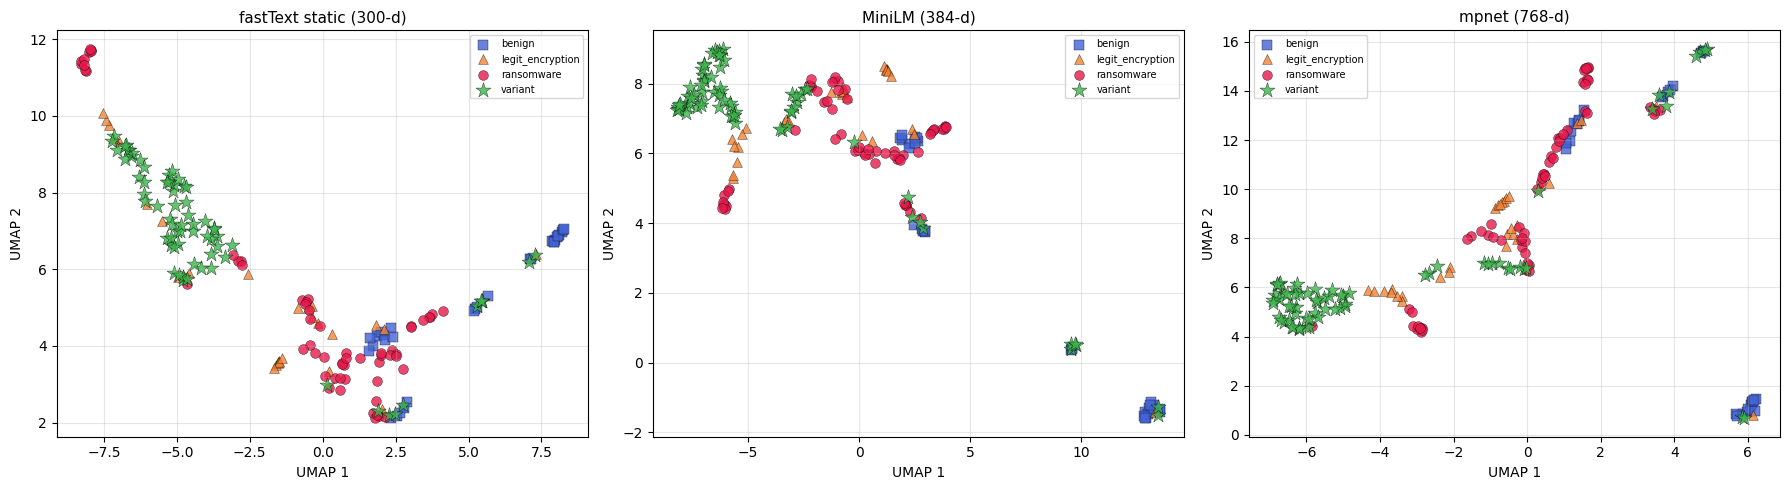

Saved: embedding_comparison_umap.png


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
NAMES = ["static","minilm","mpnet"]
emb_data = [(f"fastText static ({STATIC_DIM}-d)", X_static),
             ("MiniLM (384-d)",               X_minilm),
             ("mpnet (768-d)",                 X_mpnet)]

cmap   = {"ransomware":"#e6194b","legit_encryption":"#f58231",
           "benign":"#4363d8","variant":"#3cb44b"}
mrkmap = {"ransomware":"o","legit_encryption":"^","benign":"s","variant":"*"}

for ax, (title, X_all) in zip(axes, emb_data):
    Xm = X_all.mean(axis=1)
    r  = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                   metric="cosine", random_state=SEED)
    X2 = r.fit_transform(Xm)
    for grp in np.unique(all_3way):
        mask = all_3way == grp
        ax.scatter(X2[mask,0], X2[mask,1],
                   c=cmap[grp], marker=mrkmap[grp],
                   s=130 if grp=="variant" else 50,
                   alpha=0.8, edgecolors="k", linewidths=0.3, label=grp)
    ax.set_title(title, fontsize=11)
    ax.legend(fontsize=7); ax.grid(True, alpha=0.3)
    ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")

plt.tight_layout()
plt.savefig(FEATURES_DIR / "embedding_comparison_umap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: embedding_comparison_umap.png")


### 10. Decision table — winner selection

In [17]:
print("="*72)
print("EMBEDDING COMPARISON — FINAL DECISION")
print("="*72)

summary = {}
for n in NAMES:
    mf1 = agg(n,"val","macro_f1")
    lr  = agg(n,"val","legit_rec")
    vr  = agg(n,"variant","ransomware_rec")
    lat = latency[n]
    all_det = [v for vd in TTD[n].values() for v in vd if v is not None]
    n_det = 0
    for vname in VARIANT_CLASSES:
        mask = var_labels_arr == vname
        if mask.any():
            det_rate = (np.array([r["variant"]["preds"] for r in all_results[n]])[:,mask]
                        == ransomware_idx).mean()
            if det_rate > 0.5: n_det += 1
    summary[n] = {"macro_f1":mf1, "legit_rec":lr, "var_rec":vr,
                  "latency":lat, "n_detected":n_det,
                  "mean_ttd": np.mean(all_det) if all_det else None,
                  "feasible": lat[0] < THRESHOLD_MS}

print(f"\n{'Metric':<30}", end="")
NAMES = ["static","minilm","mpnet"]
for n in NAMES: print(f"  {n.upper():>18}", end="")
print("\n"+"-"*90)

for key, label, fmt in [
    ("macro_f1",  "3-way macro-F1",   lambda v: f"{v[0]:.3f} ± {v[1]:.3f}"),
    ("legit_rec", "Legit-enc recall", lambda v: f"{v[0]:.3f} ± {v[1]:.3f}"),
    ("var_rec",   "Variant recall",   lambda v: f"{v[0]:.3f} ± {v[1]:.3f}"),
]:
    print(f"{label:<30}", end="")
    for n in NAMES: print(f"  {fmt(summary[n][key]):>18}", end="")
    print()

print(f"\n{'Variants detected (/7)':<30}", end="")
for n in NAMES: print(f"  {summary[n]['n_detected']:>18}", end="")
print()

print(f"\n{'Latency (ms ± std)':<30}", end="")
for n in NAMES:
    m,s = summary[n]["latency"]
    tag = "" if summary[n]["feasible"] else " [DISQ]"
    print(f"  {m:.1f} ± {s:.1f}{tag:>10}", end="")
print()

print(f"\n{'Mean TTD (s)':<30}", end="")
for n in NAMES:
    ttd = summary[n]["mean_ttd"]
    print(f"  {f'{ttd:.1f}s' if ttd else 'N/A':>18}", end="")
print()

feasible = [n for n in NAMES if summary[n]["feasible"]]
print(f"\n{'='*72}")
if feasible:
    winner = max(feasible, key=lambda n:
        summary[n]["macro_f1"][0]*0.35 +
        summary[n]["legit_rec"][0]*0.30 +
        summary[n]["var_rec"][0]*0.35)
    print(f"WINNER: {winner.upper()}")
    print(f"Scoring: 35% macro-F1 + 30% legit-enc recall + 35% variant recall")
    print(f"         (among latency-feasible embedders only)")
    print(f"\n→ Update HANDOFF.md Section 0 with this result.")
else:
    print("WARNING: No embedder passes the 100 ms latency gate.")
    print("Consider batching or quantisation before deployment.")
print("="*72)


EMBEDDING COMPARISON — FINAL DECISION

Metric                                      STATIC              MINILM               MPNET
------------------------------------------------------------------------------------------
3-way macro-F1                       0.830 ± 0.124       0.962 ± 0.031       0.979 ± 0.026
Legit-enc recall                     0.822 ± 0.177       0.911 ± 0.103       0.956 ± 0.074
Variant recall                       0.309 ± 0.180       0.885 ± 0.008       0.882 ± 0.006

Variants detected (/7)                           2                   6                   6

Latency (ms ± std)              0.1 ± 0.0            23.8 ± 0.6            151.0 ± 2.3    [DISQ]

Mean TTD (s)                                 27.9s               24.3s               17.7s

WINNER: MINILM
Scoring: 35% macro-F1 + 30% legit-enc recall + 35% variant recall
         (among latency-feasible embedders only)

→ Update HANDOFF.md Section 0 with this result.


### 11. Save results to disk

In [18]:
# Save numeric results for Results.md
disk = {}
for n, runs in all_results.items():
    disk[n] = [{"fold":r["fold"],"seed":r["seed"],
                "val_macro_f1":r["val"]["macro_f1"],
                "val_legit_rec":r["val"]["legit_rec"],
                "val_ransomware_rec":r["val"]["ransomware_rec"],
                "val_benign_rec":r["val"]["benign_rec"],
                "val_accuracy":r["val"]["accuracy"],
                "var_recall":r["variant"]["ransomware_rec"]} for r in runs]

with open(FEATURES_DIR/"embedding_comparison_results.json","w") as f:
    _json.dump(disk, f, indent=2)

print("Saved:")
print("  features/raw_text_windows.pkl")
print("  features/text_sequences_static.npy")
print("  features/text_sequences_mpnet.npy")
print("  features/embedding_comparison_umap.png")
print("  features/embedding_comparison_results.json")
print()
print("="*60)
print("NOTEBOOK 06 — EMBEDDING COMPARISON — COMPLETE")
print("="*60)
print("Share the results table (Cell 6) and decision table (Cell 10)")
print("with Arshad. Update HANDOFF.md Section 0 with winner embedding.")


Saved:
  features/raw_text_windows.pkl
  features/text_sequences_static.npy
  features/text_sequences_mpnet.npy
  features/embedding_comparison_umap.png
  features/embedding_comparison_results.json

NOTEBOOK 06 — EMBEDDING COMPARISON — COMPLETE
Share the results table (Cell 6) and decision table (Cell 10)
with Arshad. Update HANDOFF.md Section 0 with winner embedding.


### 12. Optional — TF-IDF non-embedding baseline (control only)
TF-IDF is a **sparse bag-of-words**, not an embedding. It is included here
purely as a control to show that the embeddings earn their cost.
Label it as baseline in any report — not as one of the three study arms.

In [19]:
# ── TF-IDF optional baseline ──────────────────────────────────────────────
# NOTE: The vocabulary from our structured tokens is tiny (~17 unique words).
# ngram_range=(1,3) expands this significantly via bigrams/trigrams.
# SVD_DIM is set dynamically to avoid exceeding n_features.

orig_flat = [w for i in orig_indices for w in all_windows[i]]
_probe    = TfidfVectorizer(max_features=5000, sublinear_tf=True, ngram_range=(1,3))
_probe.fit(orig_flat)
vocab_size = len(_probe.vocabulary_)
SVD_DIM    = min(128, vocab_size - 1)
print(f"TF-IDF vocab (unigrams+bigrams+trigrams): {vocab_size}  →  SVD_DIM={SVD_DIM}")
del _probe

TFIDF_CACHE = FEATURES_DIR / "text_sequences_tfidf.npy"
if TFIDF_CACHE.exists():
    X_tfidf = np.load(TFIDF_CACHE).astype(np.float32)
    print(f"TF-IDF : {X_tfidf.shape}  (loaded from cache)")
    tfidf_global = None  # not needed for transform; reload if latency needed
else:
    all_flat = [w for ew in all_windows for w in ew]
    tfidf_global = make_pipeline(
        TfidfVectorizer(max_features=5000, sublinear_tf=True, ngram_range=(1,3)),
        TruncatedSVD(n_components=SVD_DIM, random_state=SEED),
        Normalizer(norm="l2")
    )
    tfidf_global.fit(orig_flat)
    X_tfidf = tfidf_global.transform(all_flat).reshape(
        len(all_windows), N_WINDOWS, SVD_DIM).astype(np.float32)
    np.save(TFIDF_CACHE, X_tfidf)
    print(f"TF-IDF : {X_tfidf.shape}  (saved to cache)")

# Run k-fold for TF-IDF — re-fit per fold to avoid leakage
def run_tfidf_fold(train_g, val_g, seed):
    tr_flat  = [w for i in train_g         for w in all_windows[i]]
    val_flat = [w for i in val_g            for w in all_windows[i]]
    var_flat = [w for i in variant_indices  for w in all_windows[i]]
    pipe = make_pipeline(
        TfidfVectorizer(max_features=5000, sublinear_tf=True, ngram_range=(1,3)),
        TruncatedSVD(n_components=SVD_DIM, random_state=seed),
        Normalizer(norm="l2")
    )
    pipe.fit(tr_flat)
    Xtr  = pipe.transform(tr_flat).reshape( len(train_g),        N_WINDOWS, SVD_DIM).astype(np.float32)
    Xval = pipe.transform(val_flat).reshape(len(val_g),           N_WINDOWS, SVD_DIM).astype(np.float32)
    Xvar = pipe.transform(var_flat).reshape(len(variant_indices), N_WINDOWS, SVD_DIM).astype(np.float32)
    model = train_model(Xtr, y_full_enc[train_g], SVD_DIM, seed)
    return eval_model(model, Xval, y_full_enc[val_g]), eval_model(model, Xvar, y_var_true)

tfidf_runs = []
for fold_i, (tr_rel, val_rel) in enumerate(skf.split(orig_indices, y_orig_enc)):
    tr_g, val_g = orig_indices[tr_rel], orig_indices[val_rel]
    for seed in SEEDS:
        vm, varm = run_tfidf_fold(tr_g, val_g, seed)
        tfidf_runs.append({"fold":fold_i,"seed":seed,"val":vm,"variant":varm})
        print(f"  fold={fold_i} seed={seed}  macro-F1={vm['macro_f1']:.3f}  "
              f"legit-rec={vm['legit_rec']:.3f}  var-rec={varm['ransomware_rec']:.3f}")

# Print TF-IDF summary next to the three main embedders
print("\n--- TF-IDF baseline vs three main embeddings ---")
all_results_with_tfidf = dict(all_results)
all_results_with_tfidf["tfidf"] = tfidf_runs
for key, label in [("macro_f1","macro-F1"), ("legit_rec","legit-rec"), ("ransomware_rec","var-rec")]:
    row = f"{label:<15}"
    kk  = "val" if key != "ransomware_rec" else "variant"
    for n in ["static","minilm","mpnet","tfidf"]:
        vals = [r[kk][key] for r in all_results_with_tfidf[n]]
        row += f"  {np.mean(vals):.3f}±{np.std(vals):.3f}"
    print(row)
print("\n(TF-IDF is a non-embedding baseline — not eligible for the winner slot.)")


TF-IDF vocab (unigrams+bigrams+trigrams): 116  →  SVD_DIM=115
TF-IDF : (190, 300, 115)  (saved to cache)
  fold=0 seed=42  macro-F1=0.944  legit-rec=0.833  var-rec=0.886
  fold=0 seed=123  macro-F1=0.944  legit-rec=0.833  var-rec=0.900
  fold=0 seed=7  macro-F1=0.944  legit-rec=0.833  var-rec=0.886
  fold=1 seed=42  macro-F1=0.944  legit-rec=0.833  var-rec=0.900
  fold=1 seed=123  macro-F1=0.944  legit-rec=0.833  var-rec=0.886
  fold=1 seed=7  macro-F1=0.944  legit-rec=0.833  var-rec=0.886
  fold=2 seed=42  macro-F1=1.000  legit-rec=1.000  var-rec=0.886
  fold=2 seed=123  macro-F1=1.000  legit-rec=1.000  var-rec=0.900
  fold=2 seed=7  macro-F1=1.000  legit-rec=1.000  var-rec=0.886
  fold=3 seed=42  macro-F1=1.000  legit-rec=1.000  var-rec=0.886
  fold=3 seed=123  macro-F1=1.000  legit-rec=1.000  var-rec=0.886
  fold=3 seed=7  macro-F1=1.000  legit-rec=1.000  var-rec=0.886


ValueError: n_components(115) must be <= n_features(114).